### PLOT PHY TRACEVIEW

Recording sampling frequency: 30000.000000 Hz
Nearest-channels source: manual (16 channels)
54 / 248 clusters flagged good (curated or KS label)
FOCUS_STRATEGY='max_good_fraction': searched 519997 time x 354 spatial candidates -> best is t=[13982.18297, 13982.23297]s, channels=[1, 31] with 3/3 spikes (100%) from good clusters
Plotting window: t=[13982.18297, 13982.23297]s, channel 1-31
38 spikes fall in the plotted window
cluster 428 good spike @ t=13982.18063s: shading window has <2 samples -- check SAMPLES_BEFORE/AFTER and fs
cluster 451 good spike @ t=13982.18457s: none of its nearest channels are in the plotted channel window (1-31) -- nothing to recolor for this one
good-cluster recolor: cluster 427 @ t=13982.18603s, 9 channels, 40 samples wide
good-cluster recolor: cluster 427 @ t=13982.18893s, 9 channels, 40 samples wide
good-cluster recolor: cluster 252 @ t=13982.19217s, 16 channels, 40 samples wide
cluster 151 good spike @ t=13982.19857s: none of its nearest channels are in th

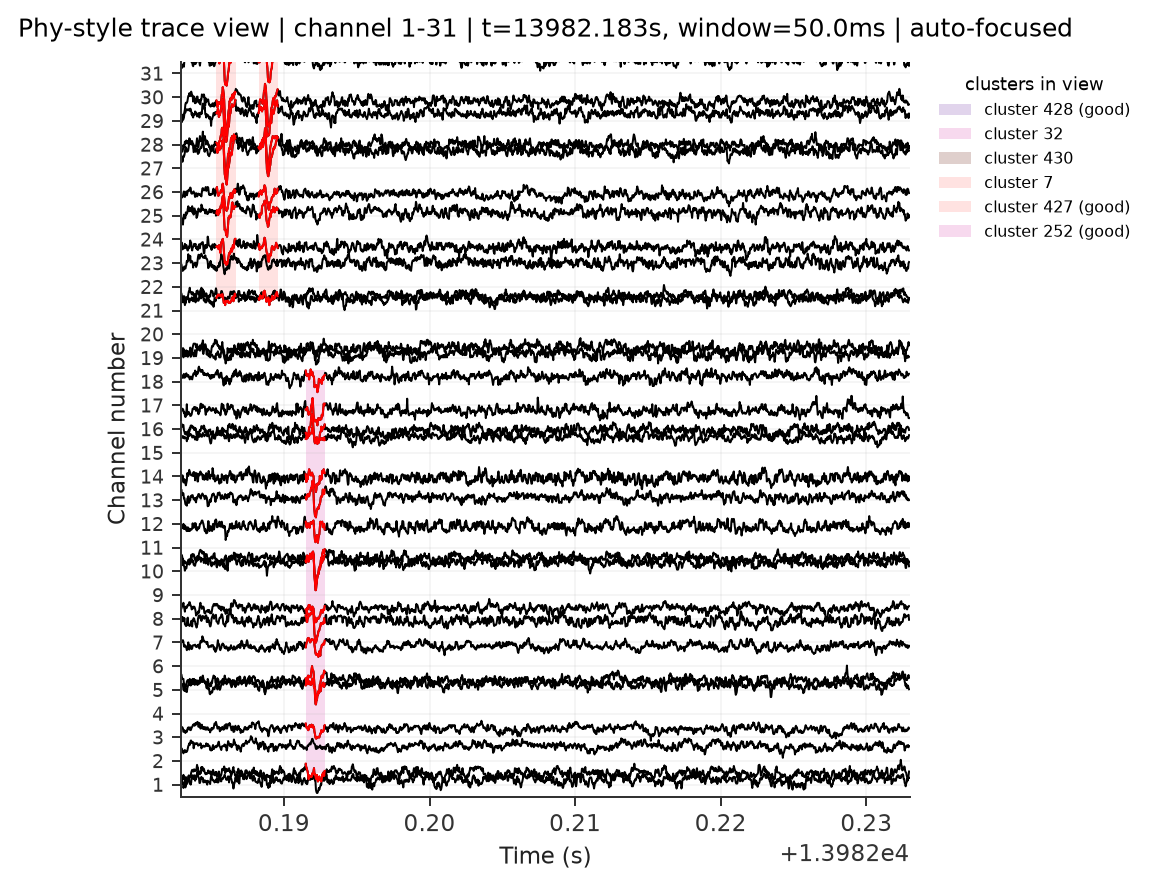

Saved: /gpfs/laur/personal/gongt/lab_meeting_plots/GLC7248_a_g3_phy_traceview_ks4.png


In [55]:
"""
Manual re-creation of phy's TraceView: raw (or preprocessed) traces with
spike shading, colored by cluster, with "good" clusters called out.

What this does, mapped to what phy shows:
  - Traces           -> same stacked-by-depth raw/preprocessed view as before.
  - Spike shading    -> for each spike in the window, shade the peak channel
                        plus the channels phy would use for PC features
                        (pc_feature_ind.npy row for that spike's template),
                        spanning SAMPLES_BEFORE/SAMPLES_AFTER samples around
                        the spike time (config below).
  - Cluster color    -> deterministic hash -> tab20 colormap, stable across runs.
  - "Good" clusters  -> good if EITHER the manually curated label
                        (cluster_group.tsv) OR the KiloSort auto label
                        (cluster_KSLabel.tsv) is "good". The peak-channel
                        segment of those spikes is redrawn bold red on top.

ASSUMPTIONS (flag these to yourself before trusting the output):
  1. channel_map.npy (KS's local channel index -> raw channel index) lines up
     with the trailing number in this recording's SpikeInterface channel ids
     (same assumption the depth-window script used). If your sorter was run
     on a channel-subset recording with re-numbered ids, this will be wrong
     and TIME/CHANNEL alignment needs an explicit override -- see
     `channel_map_override` below.
  2. The sorted recording starts at the same absolute time as the recording
     you're plotting (SORTING_TIME_OFFSET_S = 0.0). If KS was run on a
     time-cropped copy, set that offset.
  3. Nearest channels come from either pc_feature_ind.npy (phy convention) or
     a manually-set count of geometrically-nearest channels, per
     NEAREST_CHANNELS_MODE below. If pc_feature_ind.npy is missing and mode is
     "pc_feature_ind", it silently falls back to the manual/geometric method.
"""

from __future__ import annotations

import logging
from dataclasses import dataclass, field
from pathlib import Path
from typing import Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib import transforms
import spikeinterface.full as si

logging.basicConfig(level=logging.INFO, format="%(message)s")
log = logging.getLogger("phy_traceview")

# --------------------------------------------------------------------------- #
# Config -- edit these
# --------------------------------------------------------------------------- #

# Recording to draw traces from. SOURCE picks which path is used.
RAW_PATH = r"/gpfs/laur/data/0_collaboration/ceph_phys/GLC7248/GLC7248_a_g3/sliced_rec"
PREPROCESSED_PATH = ""  # fill in if you have one, e.g. ".../preprocessed"
SOURCE = "raw"  # "raw" or "preprocessed"

SORTER_OUTPUT = r"/gpfs/laur/data/0_collaboration/ceph_phys/GLC7248/GLC7248_a_g3/default_preprocessing_te6500/sorter_output"

SAVE_DIR = Path("/gpfs/laur/personal/gongt/lab_meeting_plots")
OUT_NAME = "GLC7248_a_g3_phy_traceview_ks4.png"

# Spatial window: choose "depth" (um, uses DEPTH_WINDOW_UM) or "channel"
# (ap_num, uses CHANNEL_WINDOW). Only the selected mode's range is used.
# Ignored entirely if FOCUS_ON_GOOD_UNIT is True (that picks the spatial
# window automatically instead).
SPATIAL_MODE = "channel"             # "depth" or "channel"
DEPTH_WINDOW_UM = (23.80400, 23.85400)   # (min, max) depth to include, um
CHANNEL_WINDOW = (247, 262)          # (min, max) ap_num to include, inclusive

START_S = 23.80400                   # window start, absolute recording time (ignored if focusing)
DURATION_MS = 50                     # window length (ignored if focusing, use FOCUS_WINDOW_MS instead)

SORTING_TIME_OFFSET_S = 0.0          # add if sorted recording t0 != raw t0

SAMPLES_BEFORE = 20                  # samples before spike time to shade
SAMPLES_AFTER = 20                   # samples after spike time to shade

# Where "nearest channels" (used for both shading and the good-cluster
# recolor) come from:
#   "pc_feature_ind" -> use phy's own pc_feature_ind.npy row for the spike's
#                        template (falls back to "manual" if that file is
#                        missing).
#   "manual"          -> always use N_NEAREST_FALLBACK geometrically-nearest
#                        channels (by channel_positions.npy distance to the
#                        peak channel), ignoring pc_feature_ind.npy entirely.
NEAREST_CHANNELS_MODE = "manual"     # "pc_feature_ind" or "manual"
N_NEAREST_FALLBACK = 16              # channel count used whenever "manual" applies

# channel_map.npy value -> raw ap_num override, if assumption 1 above is wrong.
# Leave as None to use channel_map.npy values directly as ap_num.
channel_map_override = None  # e.g. a dict {ks_channel_idx: raw_ap_num}

# Auto-focus: if True, ignore START_S/DURATION_MS/DEPTH_WINDOW_UM/CHANNEL_WINDOW
# above and instead automatically pick a time+space window that actually shows
# a "good" unit spiking. Handy for a quick sanity-check plot / lab meeting demo.
FOCUS_ON_GOOD_UNIT = True

# "single_unit"       -> center the window on one spike of one good cluster
#                        (FOCUS_CLUSTER_ID / FOCUS_RANDOM_SEED / FOCUS_SPIKE_INDEX below).
# "max_good_fraction" -> slide a FOCUS_WINDOW_MS window across the whole
#                        recording and use whichever one has the highest
#                        fraction of its spikes coming from good clusters --
#                        i.e. a window where good units dominate what's firing,
#                        rather than a window built around a single unit.
FOCUS_STRATEGY = "max_good_fraction"          # "single_unit" or "max_good_fraction"

FOCUS_CLUSTER_ID: Optional[int] = None  # None -> randomly pick a good cluster (see FOCUS_RANDOM_SEED)
FOCUS_RANDOM_SEED: Optional[int] = 1  # None -> different random good cluster every run;
                                          # set an int to make the random pick reproducible.
FOCUS_WINDOW_MS = 50.0                  # time window width when focusing
FOCUS_CHANNEL_SPAN = 15                 # +/- channels around the peak, used if SPATIAL_MODE == "channel"
FOCUS_DEPTH_SPAN_UM = 150.0             # +/- um around the peak, used if SPATIAL_MODE == "depth"

# Which spike (0-based, time-ordered) of the focused cluster to jump to.
# Bump this by 1 and rerun to step to the next spike; it wraps around, and the
# log line printed each run tells you the index and total count so you know
# where you are (e.g. "spike 12/311"). Only used by FOCUS_STRATEGY="single_unit".
FOCUS_SPIKE_INDEX = 10

# --- FOCUS_STRATEGY="max_good_fraction" only ---
# This searches for where to PLACE a fixed-size spatial window (still
# 2*FOCUS_CHANNEL_SPAN channels / 2*FOCUS_DEPTH_SPAN_UM um, same size the
# single_unit strategy uses) -- it does not grow the window to fit everything.
#
# A window with 1 spike that happens to be good would trivially "win" at 100%,
# so windows are only considered if they contain at least this many spikes total.
FOCUS_GOOD_FRACTION_MIN_SPIKES = 3
# Search granularity in TIME: how far the candidate window slides each step.
# None -> FOCUS_WINDOW_MS / 4 (75% overlap between consecutive candidates).
FOCUS_GOOD_FRACTION_STEP_MS: Optional[float] = None
# Search granularity in SPACE: how far the candidate spatial window slides each
# step, in the same units as FOCUS_CHANNEL_SPAN/FOCUS_DEPTH_SPAN_UM. Coarser
# (bigger) steps search faster but may miss the exact best placement.
FOCUS_GOOD_FRACTION_CHANNEL_STEP = 1        # channels, used if SPATIAL_MODE == "channel"
FOCUS_GOOD_FRACTION_DEPTH_STEP_UM = 25.0    # um, used if SPATIAL_MODE == "depth"


@dataclass
class PlotStyle:
    figsize: tuple = (6.0, 5.0)
    dpi: int = 180
    # y-axis is channel number (rows spaced 1 apart), so this is uV-per-full-row,
    # not uV-per-um. Smaller -> taller/more overlapping traces, larger -> flatter.
    uv_per_channel: float = 100
    trace_lw: float = 0.8
    trace_color: str = "black"
    shade_alpha: float = 0.28
    shade_pad_channels: float = 0.5   # padding above/below the shaded channel range
    good_color: str = "red"  # good-cluster trace segments use this color at trace_lw (no extra bolding)


STYLE = PlotStyle()

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#333333",
    "axes.labelcolor": "#222222",
    "xtick.color": "#333333",
    "ytick.color": "#333333",
    "font.size": 9,
})


# --------------------------------------------------------------------------- #
# Recording + channel table (same conventions as the depth-window script)
# --------------------------------------------------------------------------- #

import re


def _parse_ap_number(channel_id) -> int:
    m = re.search(r"(\d+)$", str(channel_id))
    if m is None:
        raise ValueError(f"Could not parse AP number from channel id: {channel_id}")
    return int(m.group(1))


def load_recording(filepath: str):
    if "_imec" in filepath:
        return si.read_spikeglx(filepath, stream_name="imec0.ap")
    else:
        return si.load(filepath)
    raise ValueError(f"Don't know how to load: {filepath}")


@dataclass
class ChannelTable:
    channel_ids: np.ndarray
    depths: np.ndarray
    ap_nums: np.ndarray

    @classmethod
    def from_recording(cls, rec) -> "ChannelTable":
        ch_ids = np.asarray(rec.get_channel_ids(), dtype=object)
        depths = rec.get_channel_locations()[:, 1].astype(float)
        ap_nums = np.array([_parse_ap_number(c) for c in ch_ids], dtype=int)
        return cls(ch_ids, depths, ap_nums)

    def sorted_by_depth(self):
        order = np.argsort(self.depths)
        return self.depths[order], self.ap_nums[order]

    def ap_to_channel_map(self) -> dict:
        return dict(zip(self.ap_nums, self.channel_ids))


def select_channels_by_window(
    depths_sorted: np.ndarray,
    aps_sorted: np.ndarray,
    mode: str,
    depth_window_um: tuple,
    channel_window: tuple,
):
    """Select channels either by depth range (um) or ap_num range, keeping
    depth-sorted order either way so plots stack top-to-bottom by depth."""
    if mode == "depth":
        lo, hi = depth_window_um
        sel = (depths_sorted >= lo) & (depths_sorted <= hi)
        desc = f"depth {lo:.0f}-{hi:.0f} µm"
    elif mode == "channel":
        lo, hi = channel_window
        sel = (aps_sorted >= lo) & (aps_sorted <= hi)
        desc = f"channel {lo:.0f}-{hi:.0f}"
    else:
        raise ValueError(f"Unknown SPATIAL_MODE: {mode!r} (expected 'depth' or 'channel')")

    if not np.any(sel):
        raise ValueError(f"No channels selected for {mode} window "
                          f"({depth_window_um if mode == 'depth' else channel_window}).")
    return sel, desc


def _load_multi_channel_traces_aligned(
    rec, ap_to_channel_sel: dict, target_times_abs: np.ndarray, start_s: float, end_s: float,
) -> dict:
    """One batched multi-channel read for every selected channel, resampled onto
    a shared time grid. This replaces doing a separate disk read per channel
    (and, previously, another one per "good" spike) -- on a network filesystem
    those per-channel round trips are what made plotting slow."""
    fs = float(rec.get_sampling_frequency())
    rec_t0 = float(rec.get_times()[0])
    rec_t1 = rec_t0 + rec.get_total_duration()
    if start_s < rec_t0 or end_s > rec_t1:
        raise ValueError(f"Requested window [{start_s:.3f}, {end_s:.3f}] s is outside recording bounds")

    start_frame = int(np.floor((start_s - rec_t0) * fs))
    end_frame = int(np.ceil((end_s - rec_t0) * fs)) + 1
    if end_frame <= start_frame + 1:
        end_frame = start_frame + 2

    ap_order = list(ap_to_channel_sel.keys())
    channel_ids = [ap_to_channel_sel[ap] for ap in ap_order]

    # return_in_uV is the current SpikeInterface kwarg; return_scaled is the
    # deprecated (pre ~0.103) name; fall back further to unscaled if neither exists.
    try:
        tr = rec.get_traces(
            start_frame=start_frame, end_frame=end_frame, channel_ids=channel_ids, return_in_uV=True,
        ).astype(float)
    except TypeError:
        try:
            tr = rec.get_traces(
                start_frame=start_frame, end_frame=end_frame, channel_ids=channel_ids, return_scaled=True,
            ).astype(float)
        except TypeError:
            tr = rec.get_traces(start_frame=start_frame, end_frame=end_frame, channel_ids=channel_ids).astype(float)

    rec_times_abs = rec_t0 + np.arange(start_frame, end_frame) / fs
    return {
        ap: np.interp(target_times_abs, rec_times_abs, tr[:, i])
        for i, ap in enumerate(ap_order)
    }


# --------------------------------------------------------------------------- #
# Phy / KiloSort sorter output
# --------------------------------------------------------------------------- #

@dataclass
class SorterOutput:
    spike_frames: np.ndarray       # (n_spikes,) int, samples relative to sorted recording
    spike_clusters: np.ndarray     # (n_spikes,) int cluster id (post-curation)
    spike_templates: np.ndarray    # (n_spikes,) int original KS template id
    templates: np.ndarray          # (n_templates, nt0, n_ks_channels)
    channel_map: np.ndarray        # (n_ks_channels,) -> raw ap_num
    channel_positions: np.ndarray  # (n_ks_channels, 2)
    pc_feature_ind: Optional[np.ndarray]  # (n_templates, n_pc_channels) -> local KS channel idx
    sample_rate: float
    good_cluster_ids: set
    _peak_cache: dict = field(default_factory=dict)
    _nearest_cache: dict = field(default_factory=dict)

    def peak_ks_channel(self, template_id: int) -> int:
        # A given template repeats across many spikes in a window, so cache it
        # rather than re-scanning the (nt0 x n_channels) waveform every time.
        if template_id not in self._peak_cache:
            wf = self.templates[template_id]  # (nt0, n_ks_channels)
            amp = wf.max(axis=0) - wf.min(axis=0)
            self._peak_cache[template_id] = int(np.argmax(amp))
        return self._peak_cache[template_id]

    def nearest_ks_channels(self, template_id: int) -> np.ndarray:
        if template_id in self._nearest_cache:
            return self._nearest_cache[template_id]

        use_pc_ind = NEAREST_CHANNELS_MODE == "pc_feature_ind" and self.pc_feature_ind is not None
        if use_pc_ind:
            result = self.pc_feature_ind[template_id].astype(int)
        else:
            if NEAREST_CHANNELS_MODE == "pc_feature_ind":
                log.warning("NEAREST_CHANNELS_MODE='pc_feature_ind' but pc_feature_ind.npy is missing -- "
                            "falling back to %d manual/geometric nearest channels", N_NEAREST_FALLBACK)
            # manual: N geometrically nearest channels to the peak channel
            peak = self.peak_ks_channel(template_id)
            d = np.linalg.norm(self.channel_positions - self.channel_positions[peak], axis=1)
            result = np.argsort(d)[:N_NEAREST_FALLBACK]

        self._nearest_cache[template_id] = result
        return result


def _read_tsv_label_map(path: Path, label_col_candidates) -> dict:
    if not path.exists():
        return {}
    df = pd.read_csv(path, sep="\t")
    label_col = next((c for c in label_col_candidates if c in df.columns), None)
    if label_col is None:
        return {}
    id_col = "cluster_id" if "cluster_id" in df.columns else df.columns[0]
    return dict(zip(df[id_col], df[label_col]))


def load_sorter_output(sorter_dir: str, sample_rate: float) -> SorterOutput:
    """sample_rate must come from the recording being plotted (rec.get_sampling_frequency()),
    not guessed from the sorter output -- see the caller in plot_phy_traceview()."""
    d = Path(sorter_dir)

    spike_frames = np.load(d / "spike_times.npy").astype(int).ravel()
    spike_clusters = np.load(d / "spike_clusters.npy").astype(int).ravel()
    spike_templates = np.load(d / "spike_templates.npy").astype(int).ravel()
    templates = np.load(d / "templates.npy")
    raw_channel_map = np.load(d / "channel_map.npy").astype(int).ravel()
    channel_positions = np.load(d / "channel_positions.npy")

    channel_map = raw_channel_map.copy()
    if channel_map_override is not None:
        channel_map = np.array([channel_map_override.get(int(i), int(i)) for i in raw_channel_map])

    pc_feature_ind = None
    pc_path = d / "pc_feature_ind.npy"
    if pc_path.exists():
        pc_feature_ind = np.load(pc_path).astype(int)
    elif NEAREST_CHANNELS_MODE == "pc_feature_ind":
        log.warning("pc_feature_ind.npy not found -- falling back to %d nearest channels by position",
                    N_NEAREST_FALLBACK)

    log.info("Nearest-channels source: %s%s", NEAREST_CHANNELS_MODE,
              f" ({N_NEAREST_FALLBACK} channels)" if NEAREST_CHANNELS_MODE == "manual" else "")

    ks_labels = _read_tsv_label_map(d / "cluster_KSLabel.tsv", ["KSLabel"])
    curated_labels = _read_tsv_label_map(d / "cluster_group.tsv", ["group"])
    if not curated_labels:
        curated_labels = _read_tsv_label_map(d / "cluster_info.tsv", ["group"])

    all_cluster_ids = np.unique(spike_clusters)
    good_cluster_ids = {
        cid for cid in all_cluster_ids
        if str(curated_labels.get(cid, "")).lower() == "good"
        # or str(ks_labels.get(cid, "")).lower() == "good"
    }
    log.info("%d / %d clusters flagged good (curated or KS label)",
             len(good_cluster_ids), len(all_cluster_ids))

    return SorterOutput(
        spike_frames=spike_frames,
        spike_clusters=spike_clusters,
        spike_templates=spike_templates,
        templates=templates,
        channel_map=channel_map,
        channel_positions=channel_positions,
        pc_feature_ind=pc_feature_ind,
        sample_rate=sample_rate,
        good_cluster_ids=good_cluster_ids,
    )


def cluster_color(cluster_id: int) -> tuple:
    cmap = plt.get_cmap("tab20")
    idx = (int(cluster_id) * 2654435761) % 20
    return cmap(idx / 20.0)


def pick_focus_window(so: SorterOutput, rec, table: "ChannelTable", cluster_id: Optional[int]):
    """Pick a (start_s, duration_ms, depth_window_um, channel_window) that is
    guaranteed to show a real spike from a good cluster, instead of you having
    to hand-pick coordinates and hope they land on something."""
    if cluster_id is None:
        if not so.good_cluster_ids:
            raise ValueError("No good clusters found in sorter output -- can't auto-focus.")
        # Random pick among all good clusters (not "most spikes" -- that biased
        # every focus run toward the same handful of high-firing-rate units).
        rng = np.random.default_rng(FOCUS_RANDOM_SEED)
        good_ids_sorted = sorted(so.good_cluster_ids)
        cluster_id = int(rng.choice(good_ids_sorted))
        log.info("FOCUS_ON_GOOD_UNIT: randomly picked cluster %d (1 of %d good clusters, seed=%s)",
                 cluster_id, len(good_ids_sorted), FOCUS_RANDOM_SEED)
    elif cluster_id not in so.good_cluster_ids:
        log.warning("FOCUS_CLUSTER_ID=%d is not flagged good -- focusing on it anyway", cluster_id)

    cluster_spike_idx = np.where(so.spike_clusters == cluster_id)[0]
    if cluster_spike_idx.size == 0:
        raise ValueError(f"Cluster {cluster_id} has no spikes at all.")

    rec_t0 = float(rec.get_times()[0])
    rec_t1 = rec_t0 + rec.get_total_duration()
    spike_times_s = (so.spike_frames[cluster_spike_idx] / so.sample_rate
                      + SORTING_TIME_OFFSET_S + rec_t0)

    # Prefer spikes that aren't right at the recording's edge, so the window
    # around them doesn't get clipped.
    margin_s = FOCUS_WINDOW_MS / 1000.0
    safe = (spike_times_s > rec_t0 + margin_s) & (spike_times_s < rec_t1 - margin_s)
    candidates = np.sort(spike_times_s[safe] if np.any(safe) else spike_times_s)

    idx = FOCUS_SPIKE_INDEX % len(candidates)  # wraps around, so any integer is valid
    spike_t = float(candidates[idx])
    log.info("FOCUS_SPIKE_INDEX=%d -> spike %d/%d for cluster %d",
              FOCUS_SPIKE_INDEX, idx + 1, len(candidates), cluster_id)

    # Dominant template for this cluster -> peak channel (a cluster can span
    # more than one KS template if it was merged during curation).
    dominant_template = int(np.bincount(so.spike_templates[cluster_spike_idx]).argmax())
    peak_ks_ch = so.peak_ks_channel(dominant_template)
    peak_ap = int(so.channel_map[peak_ks_ch])

    start_s = spike_t - FOCUS_WINDOW_MS / 2000.0
    depth_window_um, channel_window = None, None

    if SPATIAL_MODE == "depth":
        match = table.ap_nums == peak_ap
        if not np.any(match):
            raise ValueError(f"Focus peak channel ap_num={peak_ap} isn't in this recording -- "
                              f"likely a channel_map.npy / recording numbering mismatch "
                              f"(see channel_map_override).")
        peak_depth = float(table.depths[match][0])
        depth_window_um = (peak_depth - FOCUS_DEPTH_SPAN_UM, peak_depth + FOCUS_DEPTH_SPAN_UM)
    else:
        channel_window = (peak_ap - FOCUS_CHANNEL_SPAN, peak_ap + FOCUS_CHANNEL_SPAN)

    end_s = start_s + FOCUS_WINDOW_MS / 1000.0
    if SPATIAL_MODE == "depth":
        spatial_desc = f"depth {depth_window_um[0]:.0f}-{depth_window_um[1]:.0f} um"
    else:
        spatial_desc = f"channel {channel_window[0]}-{channel_window[1]}"
    log.info("FOCUS_ON_GOOD_UNIT: cluster %d, peak_ap=%d -> time window [%.5f, %.5f]s, %s",
             cluster_id, peak_ap, start_s, end_s, spatial_desc)

    return start_s, FOCUS_WINDOW_MS, depth_window_um, channel_window


def find_best_good_fraction_window(so: SorterOutput, rec, table: "ChannelTable"):
    """Jointly search over WHERE to place a fixed-size (time x space) box --
    FOCUS_WINDOW_MS wide, 2*FOCUS_CHANNEL_SPAN channels or 2*FOCUS_DEPTH_SPAN_UM
    um tall (same sizes single_unit focusing uses) -- so that the box contains
    the highest fraction of good-cluster spikes among all spikes inside it.
    This does NOT grow the spatial window to fit everything; it keeps the
    window size fixed and searches for the best place to put it, the same way
    you'd only get a 20-channel-tall plot either way.

    Candidate boxes with fewer than FOCUS_GOOD_FRACTION_MIN_SPIKES total spikes
    are skipped so a lone good spike in an otherwise-empty box can't trivially
    "win" at 100%.
    """
    if not so.good_cluster_ids:
        raise ValueError("No good clusters found in sorter output -- can't auto-focus.")

    rec_t0 = float(rec.get_times()[0])
    rec_t1 = rec_t0 + rec.get_total_duration()
    window_s = FOCUS_WINDOW_MS / 1000.0
    step_s = (FOCUS_GOOD_FRACTION_STEP_MS or FOCUS_WINDOW_MS / 4.0) / 1000.0

    spike_times_s = so.spike_frames / so.sample_rate + SORTING_TIME_OFFSET_S + rec_t0
    is_good = np.isin(so.spike_clusters, list(so.good_cluster_ids))

    # Peak channel per spike, vectorized over all templates at once (same
    # peak-channel definition as SorterOutput.peak_ks_channel, just batched so
    # we're not doing a per-spike Python-level lookup below).
    amp_all = so.templates.max(axis=1) - so.templates.min(axis=1)   # (n_templates, n_ks_channels)
    peak_ks_all = np.argmax(amp_all, axis=1)                        # (n_templates,)
    peak_ap_all = so.channel_map[peak_ks_all]                       # (n_templates,) -> ap_num
    peak_ap_per_spike = peak_ap_all[so.spike_templates]             # (n_spikes,)

    # Sort everything by time once. Time-window boundaries (los/his) don't
    # depend on which spatial window we're testing, so they're computed once
    # here and reused across every spatial candidate in the loop below.
    order = np.argsort(spike_times_s)
    sorted_times = spike_times_s[order]
    sorted_good = is_good[order]
    sorted_ap = peak_ap_per_spike[order]

    starts_t = np.arange(rec_t0, max(rec_t1 - window_s, rec_t0), step_s)
    if starts_t.size == 0:
        starts_t = np.array([rec_t0])
    los = np.searchsorted(sorted_times, starts_t, side="left")
    his = np.searchsorted(sorted_times, starts_t + window_s, side="left")

    if SPATIAL_MODE == "depth":
        ap_to_depth = dict(zip(table.ap_nums, table.depths))
        sorted_spatial = np.array([ap_to_depth.get(int(a), np.nan) for a in sorted_ap])
        half_span = float(FOCUS_DEPTH_SPAN_UM)
        step_spatial = float(FOCUS_GOOD_FRACTION_DEPTH_STEP_UM)
        lo_bound, hi_bound = float(np.nanmin(table.depths)), float(np.nanmax(table.depths))
        unit = "um"
    else:
        sorted_spatial = sorted_ap.astype(float)
        half_span = float(FOCUS_CHANNEL_SPAN)
        step_spatial = float(FOCUS_GOOD_FRACTION_CHANNEL_STEP)
        lo_bound, hi_bound = float(table.ap_nums.min()), float(table.ap_nums.max())
        unit = "channels"

    width = 2.0 * half_span
    starts_sp = np.arange(lo_bound, max(hi_bound - width, lo_bound) + 1e-9, step_spatial)
    if starts_sp.size == 0:
        starts_sp = np.array([lo_bound])

    valid = ~np.isnan(sorted_spatial)
    best = None  # (fraction, good, total, t_start, sp_start)

    for sp_start in starts_sp:
        chan_mask = valid & (sorted_spatial >= sp_start) & (sorted_spatial < sp_start + width)
        if not np.any(chan_mask):
            continue
        cum_total = np.concatenate(([0], np.cumsum(chan_mask)))
        cum_good = np.concatenate(([0], np.cumsum(chan_mask & sorted_good)))

        totals = cum_total[his] - cum_total[los]
        goods = cum_good[his] - cum_good[los]
        fractions = np.where(totals >= FOCUS_GOOD_FRACTION_MIN_SPIKES,
                              goods / np.maximum(totals, 1), -1.0)
        idx = int(np.argmax(fractions))
        if fractions[idx] < 0:
            continue
        if best is None or fractions[idx] > best[0]:
            best = (float(fractions[idx]), int(goods[idx]), int(totals[idx]),
                    float(starts_t[idx]), float(sp_start))

    if best is None:
        raise ValueError(f"No {FOCUS_WINDOW_MS:.0f}ms x {width:.0f}{unit} window has >= "
                          f"FOCUS_GOOD_FRACTION_MIN_SPIKES={FOCUS_GOOD_FRACTION_MIN_SPIKES} spikes -- "
                          f"lower that threshold, widen the window/span, or shrink the step sizes.")

    fraction, best_good, best_total, start_s, sp_start = best
    log.info("FOCUS_STRATEGY='max_good_fraction': searched %d time x %d spatial candidates -> "
             "best is t=[%.5f, %.5f]s, %s=[%.0f, %.0f] with %d/%d spikes (%.0f%%) from good clusters",
             len(starts_t), len(starts_sp), start_s, start_s + window_s, unit,
             sp_start, sp_start + width, best_good, best_total, 100.0 * fraction)

    depth_window_um, channel_window = None, None
    if SPATIAL_MODE == "depth":
        depth_window_um = (sp_start, sp_start + width)
    else:
        channel_window = (int(round(sp_start)), int(round(sp_start + width)))

    return start_s, FOCUS_WINDOW_MS, depth_window_um, channel_window


# --------------------------------------------------------------------------- #
# Plot
# --------------------------------------------------------------------------- #

def plot_phy_traceview() -> None:
    path = RAW_PATH if SOURCE == "raw" else PREPROCESSED_PATH
    rec = load_recording(path)
    sample_rate = float(rec.get_sampling_frequency())
    log.info("Recording sampling frequency: %.6f Hz", sample_rate)
    so = load_sorter_output(SORTER_OUTPUT, sample_rate)
    table = ChannelTable.from_recording(rec)

    start_s, duration_ms = START_S, DURATION_MS
    depth_window_um, channel_window = DEPTH_WINDOW_UM, CHANNEL_WINDOW

    if FOCUS_ON_GOOD_UNIT:
        if FOCUS_STRATEGY == "max_good_fraction":
            start_s, duration_ms, focus_depth_window, focus_channel_window = find_best_good_fraction_window(
                so, rec, table
            )
        elif FOCUS_STRATEGY == "single_unit":
            start_s, duration_ms, focus_depth_window, focus_channel_window = pick_focus_window(
                so, rec, table, FOCUS_CLUSTER_ID
            )
        else:
            raise ValueError(f"Unknown FOCUS_STRATEGY: {FOCUS_STRATEGY!r} "
                              f"(expected 'single_unit' or 'max_good_fraction')")
        if focus_depth_window is not None:
            depth_window_um = focus_depth_window
        if focus_channel_window is not None:
            channel_window = focus_channel_window

    depths_sorted, aps_sorted = table.sorted_by_depth()
    sel, window_desc = select_channels_by_window(
        depths_sorted, aps_sorted, SPATIAL_MODE, depth_window_um, channel_window
    )

    depths_sel = depths_sorted[sel]
    ap_sel = np.sort(aps_sorted[sel])  # y-axis is channel number, so order by that
    baselines_sel = ap_sel.astype(float)  # channel numbers are already unique -> use directly as y position
    ap_to_baseline = dict(zip(ap_sel, baselines_sel))
    ap_to_channel = table.ap_to_channel_map()

    fs = sample_rate
    rec_t0 = float(rec.get_times()[0])
    end_s = start_s + duration_ms / 1000.0
    n_samples = int(round(duration_ms / 1000.0 * fs))
    target_times_abs = start_s + np.arange(n_samples) / fs

    log.info("Plotting window: t=[%.5f, %.5f]s, %s", start_s, end_s, window_desc)

    fig, ax = plt.subplots(figsize=STYLE.figsize, dpi=STYLE.dpi)

    # 1) base traces -- one batched multi-channel read for every selected
    # channel (instead of one disk read per channel), reused below for the
    # good-cluster overlay too.
    ap_to_channel_sel = {ap: ap_to_channel[ap] for ap in ap_sel if ap in ap_to_channel}
    traces_by_ap = _load_multi_channel_traces_aligned(rec, ap_to_channel_sel, target_times_abs, start_s, end_s)

    for ap_num, y0 in zip(ap_sel, baselines_sel):
        if ap_num not in traces_by_ap:
            continue
        trace = traces_by_ap[ap_num]
        ax.plot(target_times_abs, y0 + trace / STYLE.uv_per_channel, color=STYLE.trace_color,
                lw=STYLE.trace_lw, zorder=2)

    # 2) spike shading + good-cluster bold overlay
    win_pad_s = 0.003  # small pad so spikes whose window straddles the edge still get pulled in
    spike_times_s = so.spike_frames / so.sample_rate + SORTING_TIME_OFFSET_S + rec_t0
    in_window = (spike_times_s >= start_s - win_pad_s) & (spike_times_s <= end_s + win_pad_s)
    spike_idx = np.where(in_window)[0]
    log.info("%d spikes fall in the plotted window", len(spike_idx))

    legend_entries = {}
    n_good_spikes_in_window = 0
    n_good_overlays_drawn = 0

    for i in spike_idx:
        template_id = so.spike_templates[i]
        cluster_id = so.spike_clusters[i]
        spike_t = spike_times_s[i]

        t_before = SAMPLES_BEFORE / fs
        t_after = SAMPLES_AFTER / fs
        win_start, win_end = spike_t - t_before, spike_t + t_after

        peak_ks_ch = so.peak_ks_channel(template_id)
        nearest_ks_chs = so.nearest_ks_channels(template_id)
        peak_ap = int(so.channel_map[peak_ks_ch])
        color = cluster_color(cluster_id)
        is_good = cluster_id in so.good_cluster_ids

        # Only the channels that are both "nearest" for this template AND inside
        # our plotted channel window get shaded -- this is also what determines
        # whether the spike is relevant to this view at all.
        shaded_aps = [int(so.channel_map[ks_ch]) for ks_ch in nearest_ks_chs
                      if int(so.channel_map[ks_ch]) in ap_to_baseline]

        drew_something = False

        if shaded_aps:
            y_lo = min(ap_to_baseline[a] for a in shaded_aps) - STYLE.shade_pad_channels
            y_hi = max(ap_to_baseline[a] for a in shaded_aps) + STYLE.shade_pad_channels
            rect = patches.Rectangle(
                (win_start, y_lo), win_end - win_start, y_hi - y_lo,
                facecolor=color, alpha=STYLE.shade_alpha, edgecolor="none", zorder=1,
            )
            ax.add_patch(rect)
            drew_something = True

        if is_good:
            n_good_spikes_in_window += 1
            if not shaded_aps:
                log.warning("cluster %d good spike @ t=%.5fs: none of its nearest channels are in the "
                            "plotted channel window (%d-%d) -- nothing to recolor for this one",
                            cluster_id, spike_t, min(ap_to_baseline), max(ap_to_baseline))
            else:
                mask = (target_times_abs >= max(win_start, start_s)) & (target_times_abs <= min(win_end, end_s))
                if mask.sum() >= 2:
                    seg_times = target_times_abs[mask]
                    # Recolor the segment red on every shaded (nearest) channel, not just the
                    # peak -- same line width as the raw trace, so it reads as "this stretch of
                    # trace is red" rather than an extra bold line drawn on top of it.
                    for ap_num in shaded_aps:
                        if ap_num not in traces_by_ap:
                            continue
                        y0 = ap_to_baseline[ap_num]
                        trace_seg = traces_by_ap[ap_num][mask]
                        ax.plot(seg_times, y0 + trace_seg / STYLE.uv_per_channel, color=STYLE.good_color,
                                lw=STYLE.trace_lw, zorder=3)
                    drew_something = True
                    n_good_overlays_drawn += 1
                    log.info("good-cluster recolor: cluster %d @ t=%.5fs, %d channels, %d samples wide",
                             cluster_id, spike_t, len(shaded_aps), int(mask.sum()))
                else:
                    log.warning("cluster %d good spike @ t=%.5fs: shading window has <2 samples -- "
                                "check SAMPLES_BEFORE/AFTER and fs", cluster_id, spike_t)

        if not drew_something:
            continue  # this spike's channels don't overlap the plotted window at all

        label = f"cluster {cluster_id}" + (" (good)" if is_good else "")
        legend_entries[cluster_id] = (color, label)

    log.info("%d good-cluster spikes in window, %d bold overlays drawn",
              n_good_spikes_in_window, n_good_overlays_drawn)

    # axes cosmetics
    ax.set_xlim(start_s, end_s)
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Channel number")
    focus_tag = " | auto-focused" if FOCUS_ON_GOOD_UNIT else ""
    ax.set_title(f"Phy-style trace view | {window_desc} | "
                 f"t={start_s:.3f}s, window={duration_ms:.1f}ms{focus_tag}", fontsize=10, pad=10)
    ax.grid(True, alpha=0.12)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.set_yticks(ap_sel)
    ax.set_yticklabels([f"{a:d}" for a in ap_sel], fontsize=7.5)
    # Pin the y-range to the selected channels (+ half a row of padding) so a
    # stray large-amplitude sample can't blow the axis out and squash the ticks.
    ax.set_ylim(float(ap_sel.min()) - 0.5, float(ap_sel.max()) + 0.5)

    if legend_entries:
        handles = [patches.Patch(facecolor=c, alpha=STYLE.shade_alpha, label=l)
                   for c, l in legend_entries.values()]
        ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.02, 1.0),
                  fontsize=6.5, frameon=False, title="clusters in view", title_fontsize=7)

    fig.tight_layout()
    SAVE_DIR.mkdir(parents=True, exist_ok=True)
    out_path = SAVE_DIR / OUT_NAME
    fig.savefig(out_path, dpi=STYLE.dpi, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    log.info("Saved: %s", out_path)


if __name__ == "__main__":
    plot_phy_traceview()

###  PLOT CLUSTER SPIKES

Recording sampling frequency: 30000.000000 Hz
Cluster 252: 42264 total spikes, curated=good, KS=good
Peak channel: 10. Nearest 10 channels: [10, 8, 12, 11, 14, 6, 7, 15, 9, 13]
Extracted 500/500 waveforms (some may be dropped near recording edges)


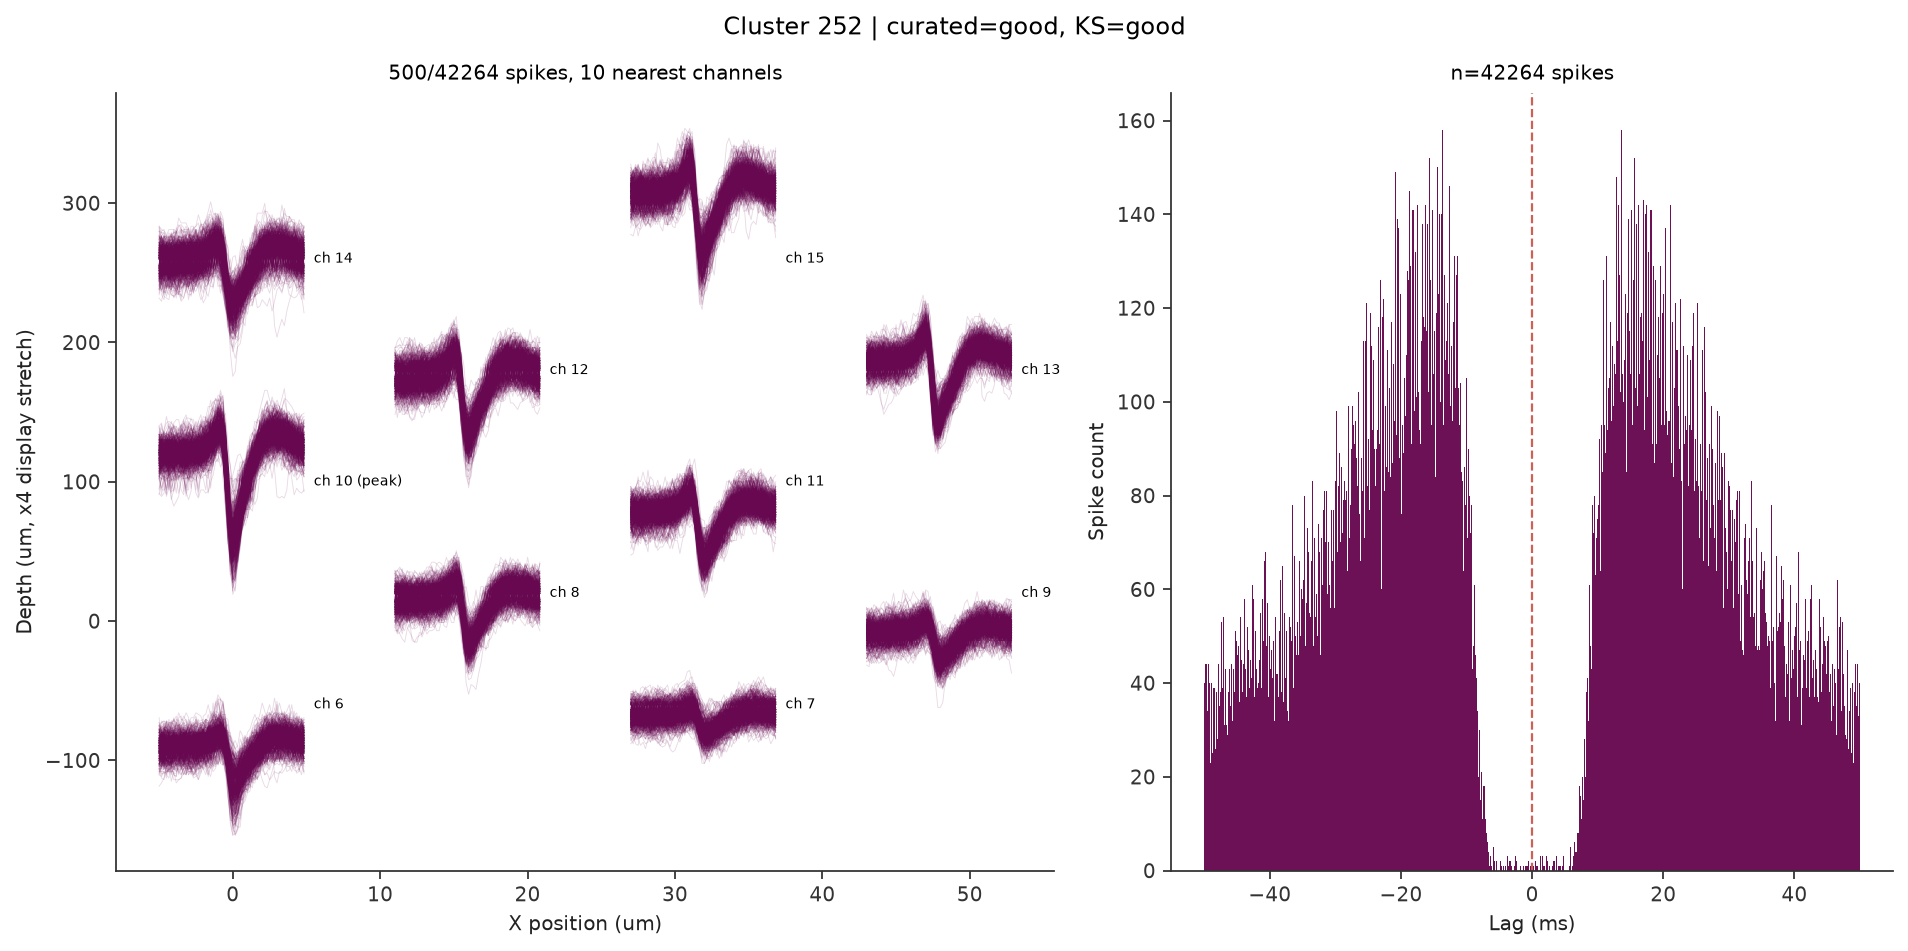

Saved: /gpfs/laur/personal/gongt/lab_meeting_plots/cluster252_waveforms_acg.png


In [61]:
"""
Per-cluster sanity-check plot: raw waveforms on the N nearest channels,
arranged at their true spatial (probe) positions, plus the autocorrelogram
(ACG) of the spike train -- both in one figure.

  - Waveforms -> for a chosen CLUSTER_ID, take (up to) N_SPIKES_TO_PLOT of its
    spikes, pull a short raw snippet around each spike time on its
    N_NEAREST_CHANNELS, and overlay them (thin, semi-transparent), each mini
    trace drawn at that channel's real (x, y) position on the probe -- same
    idea as phy's WaveformView.
  - ACG -> pairwise spike-time-difference histogram over the cluster's full
    spike train (not just the plotted subset), using a two-pointer scan
    instead of all-pairs so it stays fast even for high-firing-rate units.

ASSUMPTIONS (same as the traceview script):
  1. channel_map.npy values line up with the trailing number in this
     recording's SpikeInterface channel ids. Override via channel_map_override
     if not. (Channel *geometry* for the waveform panel comes straight from
     channel_positions.npy, so it's unaffected by this assumption -- only
     which raw channel gets read for a given KS channel depends on it.)
  2. The sorted recording starts at the same absolute time as the recording
     you're plotting (SORTING_TIME_OFFSET_S = 0.0 unless you know otherwise).
"""

from __future__ import annotations

import re
import logging
from dataclasses import dataclass, field
from pathlib import Path
from typing import Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spikeinterface.full as si

logging.basicConfig(level=logging.INFO, format="%(message)s")
log = logging.getLogger("cluster_waveforms_acg")

# --------------------------------------------------------------------------- #
# Config -- edit these
# --------------------------------------------------------------------------- #
RAW_PATH = r"/gpfs/laur/data/0_collaboration/ceph_phys/GLC7248/GLC7248_a_g3/sliced_rec"
PREPROCESSED_PATH = ""  # fill in if you have one, e.g. ".../preprocessed"
SOURCE = "raw"  # "raw" or "preprocessed"

SORTER_OUTPUT = r"/gpfs/laur/data/0_collaboration/ceph_phys/GLC7248/GLC7248_a_g3/default_preprocessing_te6500/sorter_output"

SAVE_DIR = Path("/gpfs/laur/personal/gongt/lab_meeting_plots")

CLUSTER_ID = 252  # <-- set the cluster you want to plot

N_NEAREST_CHANNELS = 10       # channels to show, nearest-to-peak first
N_SPIKES_TO_PLOT = 500        # random subsample of this cluster's spikes to overlay
RANDOM_SEED = 0

WAVEFORM_SAMPLES_BEFORE = 30  # samples before spike time to extract
WAVEFORM_SAMPLES_AFTER = 30   # samples after spike time to extract

ACG_WINDOW_MS = 50.0          # +/- window for the autocorrelogram
ACG_BIN_MS = 0.1              # bin width -- window is snapped to an exact multiple of this

SORTING_TIME_OFFSET_S = 0.0   # add if sorted recording t0 != raw t0
N_NEAREST_FALLBACK = 32       # only used if pc_feature_ind.npy is missing

# channel_map.npy value -> raw ap_num override, if the assumption above is wrong.
channel_map_override = None  # e.g. a dict {ks_channel_idx: raw_ap_num}


@dataclass
class PlotStyle:
    figsize: tuple = (12.0, 6.0)       # whole combined figure
    dpi: int = 160
    width_ratios: tuple = (1.3, 1.0)   # waveform panel vs ACG panel width

    color: str = "#680851F6"             # shared color: waveform traces AND acg bars
    trace_lw: float = 0.4
    trace_alpha: float = 0.15

    # "magnitude" of the waveforms: uV represented by 1 real um of vertical
    # space. This is a *voltage* scale, so it interacts with the true
    # inter-channel spacing (often only ~15-20 um on Neuropixels) -- a spike
    # of e.g. 200 uV divided by uv_per_um=1 draws 200 um tall, which is way
    # taller than the gap between channel rows and will look like one big
    # overlapping smear across many rows. Increase this (e.g. 20-50) to keep
    # each channel's waveform contained near its own row, or use
    # vertical_stretch below to open up room between rows instead.
    uv_per_um: float = 2
    # horizontal footprint (in um) each mini waveform trace occupies, centered
    # on its channel's true x position.
    time_width_um: float = 10.0

    # Multiplies the real inter-channel distance (around the group's mean
    # depth) purely for display -- lets you add breathing room between rows
    # without changing the amplitude scale above. 1.0 = true geometry;
    # >1.0 spreads channels apart; <1.0 packs them closer.
    vertical_stretch: float = 4.0

    acg_zero_line_color: str = "#c0392b"


STYLE = PlotStyle()

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#333333",
    "axes.labelcolor": "#222222",
    "xtick.color": "#333333",
    "ytick.color": "#333333",
    "font.size": 9,
})


# --------------------------------------------------------------------------- #
# Recording + channel table
# --------------------------------------------------------------------------- #

def _parse_ap_number(channel_id) -> int:
    m = re.search(r"(\d+)$", str(channel_id))
    if m is None:
        raise ValueError(f"Could not parse AP number from channel id: {channel_id}")
    return int(m.group(1))


def load_recording(filepath: str):
    if "_imec" in filepath:
        return si.read_spikeglx(filepath, stream_name="imec0.ap")
    else: 
        return si.load(filepath)
    raise ValueError(f"Don't know how to load: {filepath}")


@dataclass
class ChannelTable:
    channel_ids: np.ndarray
    ap_nums: np.ndarray

    @classmethod
    def from_recording(cls, rec) -> "ChannelTable":
        ch_ids = np.asarray(rec.get_channel_ids(), dtype=object)
        ap_nums = np.array([_parse_ap_number(c) for c in ch_ids], dtype=int)
        return cls(ch_ids, ap_nums)

    def ap_to_channel_map(self) -> dict:
        return dict(zip(self.ap_nums, self.channel_ids))


# --------------------------------------------------------------------------- #
# Phy / KiloSort sorter output
# --------------------------------------------------------------------------- #

@dataclass
class SorterOutput:
    spike_frames: np.ndarray
    spike_clusters: np.ndarray
    spike_templates: np.ndarray
    templates: np.ndarray          # (n_templates, nt0, n_ks_channels)
    channel_map: np.ndarray        # (n_ks_channels,) -> raw ap_num
    channel_positions: np.ndarray  # (n_ks_channels, 2) -> [x_um, y_um], ground-truth geometry
    pc_feature_ind: Optional[np.ndarray]
    sample_rate: float
    good_cluster_ids: set
    ks_labels: dict
    curated_labels: dict
    _peak_cache: dict = field(default_factory=dict)
    _nearest_cache: dict = field(default_factory=dict)

    def peak_ks_channel(self, template_id: int) -> int:
        if template_id not in self._peak_cache:
            wf = self.templates[template_id]
            amp = wf.max(axis=0) - wf.min(axis=0)
            self._peak_cache[template_id] = int(np.argmax(amp))
        return self._peak_cache[template_id]

    def nearest_ks_channels(self, template_id: int, n: int) -> np.ndarray:
        """Return the n channels closest to the peak channel, always sorted by
        true geometric distance (channel_positions.npy). pc_feature_ind.npy,
        when available, is only used to narrow the *candidate pool* -- its row
        order isn't trusted to already be nearest-first, since that's a
        Kilosort convention, not a guarantee every sorter's phy export
        follows (e.g. MountainSort5's export_to_phy doesn't)."""
        key = (template_id, n)
        if key in self._nearest_cache:
            return self._nearest_cache[key]

        peak = self.peak_ks_channel(template_id)
        if self.pc_feature_ind is not None:
            candidates = self.pc_feature_ind[template_id].astype(int)
        else:
            candidates = np.arange(self.channel_positions.shape[0])

        d = np.linalg.norm(self.channel_positions[candidates] - self.channel_positions[peak], axis=1)
        result = candidates[np.argsort(d)][:n]

        self._nearest_cache[key] = result
        return result

    def cluster_label(self, cluster_id: int) -> str:
        curated = str(self.curated_labels.get(cluster_id, "")).strip()
        ks = str(self.ks_labels.get(cluster_id, "")).strip()
        if curated:
            return f"curated={curated}" + (f", KS={ks}" if ks else "")
        return f"KS={ks}" if ks else "unlabeled"


def _read_tsv_label_map(path: Path, label_col_candidates) -> dict:
    if not path.exists():
        return {}
    df = pd.read_csv(path, sep="\t")
    label_col = next((c for c in label_col_candidates if c in df.columns), None)
    if label_col is None:
        return {}
    id_col = "cluster_id" if "cluster_id" in df.columns else df.columns[0]
    return dict(zip(df[id_col], df[label_col]))


def load_sorter_output(sorter_dir: str, sample_rate: float) -> SorterOutput:
    """sample_rate must come from the recording being plotted (rec.get_sampling_frequency()),
    not guessed from the sorter output."""
    d = Path(sorter_dir)

    spike_frames = np.load(d / "spike_times.npy").astype(int).ravel()
    spike_clusters = np.load(d / "spike_clusters.npy").astype(int).ravel()
    spike_templates = np.load(d / "spike_templates.npy").astype(int).ravel()
    templates = np.load(d / "templates.npy")
    raw_channel_map = np.load(d / "channel_map.npy").astype(int).ravel()
    channel_positions = np.load(d / "channel_positions.npy")

    channel_map = raw_channel_map.copy()
    if channel_map_override is not None:
        channel_map = np.array([channel_map_override.get(int(i), int(i)) for i in raw_channel_map])

    pc_feature_ind = None
    pc_path = d / "pc_feature_ind.npy"
    if pc_path.exists():
        pc_feature_ind = np.load(pc_path).astype(int)
    else:
        log.warning("pc_feature_ind.npy not found -- falling back to nearest-by-position channels")

    ks_labels = _read_tsv_label_map(d / "cluster_KSLabel.tsv", ["KSLabel"])
    curated_labels = _read_tsv_label_map(d / "cluster_group.tsv", ["group"])
    if not curated_labels:
        curated_labels = _read_tsv_label_map(d / "cluster_info.tsv", ["group"])

    all_cluster_ids = np.unique(spike_clusters)
    good_cluster_ids = {
        cid for cid in all_cluster_ids
        if str(curated_labels.get(cid, "")).lower() == "good"
        or str(ks_labels.get(cid, "")).lower() == "good"
    }

    return SorterOutput(
        spike_frames=spike_frames,
        spike_clusters=spike_clusters,
        spike_templates=spike_templates,
        templates=templates,
        channel_map=channel_map,
        channel_positions=channel_positions,
        pc_feature_ind=pc_feature_ind,
        sample_rate=sample_rate,
        good_cluster_ids=good_cluster_ids,
        ks_labels=ks_labels,
        curated_labels=curated_labels,
    )


# --------------------------------------------------------------------------- #
# Waveform extraction
# --------------------------------------------------------------------------- #

def extract_waveforms(
    rec, channel_ids: list, spike_times_s: np.ndarray, samples_before: int, samples_after: int,
) -> np.ndarray:
    """One small multi-channel read per spike. Returns (n_valid_spikes, n_samples, n_channels);
    spikes whose window would run off the start/end of the recording are dropped."""
    fs = float(rec.get_sampling_frequency())
    rec_t0 = float(rec.get_times()[0])
    n_frames = rec.get_num_frames()

    waveforms = []
    for spike_t in spike_times_s:
        center_frame = int(round((spike_t - rec_t0) * fs))
        start_frame = center_frame - samples_before
        end_frame = center_frame + samples_after
        if start_frame < 0 or end_frame >= n_frames:
            continue
        try:
            wf = rec.get_traces(start_frame=start_frame, end_frame=end_frame,
                                 channel_ids=channel_ids, return_in_uV=True).astype(float)
        except TypeError:
            try:
                wf = rec.get_traces(start_frame=start_frame, end_frame=end_frame,
                                     channel_ids=channel_ids, return_scaled=True).astype(float)
            except TypeError:
                wf = rec.get_traces(start_frame=start_frame, end_frame=end_frame,
                                     channel_ids=channel_ids).astype(float)
        waveforms.append(wf)

    if not waveforms:
        return np.empty((0, samples_before + samples_after, len(channel_ids)))
    return np.stack(waveforms, axis=0)


# --------------------------------------------------------------------------- #
# ACG
# --------------------------------------------------------------------------- #

def compute_acg(spike_times_s: np.ndarray, window_ms: float, bin_ms: float):
    """Symmetric autocorrelogram via a two-pointer scan (fast even for
    high-firing units) instead of an O(n^2) all-pairs difference matrix.

    Bin edges are built with integer arithmetic (arange over bin counts, not
    linspace over the window) so every bin is *exactly* bin_ms wide -- if
    window_ms isn't an exact multiple of bin_ms, the window is snapped
    outward to the nearest multiple and a warning is logged, rather than
    silently producing slightly-unequal bins.
    """
    bin_s = bin_ms / 1000.0
    half_bins = int(np.ceil((window_ms / 1000.0) / bin_s))
    actual_window_ms = half_bins * bin_ms
    if not np.isclose(actual_window_ms, window_ms):
        log.warning("ACG_WINDOW_MS=%.3f isn't a multiple of ACG_BIN_MS=%.3f -- using %.3f instead "
                    "so every bin is exactly the same width", window_ms, bin_ms, actual_window_ms)

    edges = np.arange(-half_bins, half_bins + 1) * bin_s  # exact multiples of bin_s, no fp drift
    n_bins = len(edges) - 1
    window_s = half_bins * bin_s
    counts = np.zeros(n_bins, dtype=np.int64)

    times = np.sort(spike_times_s)
    n = len(times)
    j_hi = 1
    for i in range(n):
        if j_hi < i + 1:
            j_hi = i + 1
        while j_hi < n and times[j_hi] - times[i] <= window_s:
            j_hi += 1
        if j_hi > i + 1:
            diffs = times[i + 1:j_hi] - times[i]
            idx_pos = np.clip(np.searchsorted(edges, diffs, side="right") - 1, 0, n_bins - 1)
            idx_neg = np.clip(np.searchsorted(edges, -diffs, side="right") - 1, 0, n_bins - 1)
            np.add.at(counts, idx_pos, 1)
            np.add.at(counts, idx_neg, 1)

    return edges, counts


# --------------------------------------------------------------------------- #
# Plot
# --------------------------------------------------------------------------- #

def plot_waveforms_spatial(ax, ap_order, positions_by_ap, peak_ap, waveforms, style):
    """Draw each channel's overlaid waveforms at that channel's real (x, y)
    probe position, instead of a simple linear stack. The real y (depth) is
    stretched by style.vertical_stretch around the group's mean depth purely
    for display, so you can open up room between rows independently of the
    voltage scale (uv_per_um)."""
    n_spikes, n_samples, n_channels = waveforms.shape
    span = WAVEFORM_SAMPLES_BEFORE + WAVEFORM_SAMPLES_AFTER
    t_norm = (np.arange(n_samples) - WAVEFORM_SAMPLES_BEFORE) / span  # roughly -0.5 .. +0.5

    y_center = float(np.mean([positions_by_ap[a][1] for a in ap_order]))

    def display_y(y_real: float) -> float:
        return y_center + (y_real - y_center) * style.vertical_stretch

    for ci, ap_num in enumerate(ap_order):
        x, y_real = positions_by_ap[ap_num]
        y = display_y(y_real)
        x_plot = x + t_norm * style.time_width_um
        for wf in waveforms[:, :, ci]:
            y_plot = y + wf / style.uv_per_um
            ax.plot(x_plot, y_plot, color=style.color, lw=style.trace_lw,
                    alpha=style.trace_alpha, zorder=2)

        tag = " (peak)" if ap_num == peak_ap else ""
        ax.text(x + style.time_width_um * 0.55, y, f"ch {ap_num}{tag}",
                fontsize=6.5, va="center", ha="left")

    ax.set_xlabel("X position (um)")
    ax.set_ylabel(f"Depth (um, x{style.vertical_stretch:g} display stretch)"
                   if style.vertical_stretch != 1.0 else "Depth (um)")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def plot_acg_panel(ax, edges, counts, style):
    edges_ms = edges * 1000.0
    bin_width_ms = edges_ms[1] - edges_ms[0]  # exact, identical for every bin
    ax.bar(edges_ms[:-1], counts, width=bin_width_ms, align="edge",
           color=style.color, edgecolor="none", linewidth=0)
    ax.axvline(0, color=style.acg_zero_line_color, lw=1.0, ls="--", alpha=0.8)
    ax.set_xlabel("Lag (ms)")
    ax.set_ylabel("Spike count")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


# --------------------------------------------------------------------------- #
# Main
# --------------------------------------------------------------------------- #

def plot_cluster(cluster_id: int) -> None:
    path = RAW_PATH if SOURCE == "raw" else PREPROCESSED_PATH
    rec = load_recording(path)
    sample_rate = float(rec.get_sampling_frequency())
    log.info("Recording sampling frequency: %.6f Hz", sample_rate)
    so = load_sorter_output(SORTER_OUTPUT, sample_rate)
    table = ChannelTable.from_recording(rec)
    ap_to_channel = table.ap_to_channel_map()

    rec_t0 = float(rec.get_times()[0])
    cluster_spike_idx = np.where(so.spike_clusters == cluster_id)[0]
    if cluster_spike_idx.size == 0:
        raise ValueError(f"Cluster {cluster_id} has no spikes in this sorter output.")

    spike_times_s = (so.spike_frames[cluster_spike_idx] / so.sample_rate
                      + SORTING_TIME_OFFSET_S + rec_t0)
    n_total_spikes = len(spike_times_s)
    label = so.cluster_label(cluster_id)
    log.info("Cluster %d: %d total spikes, %s", cluster_id, n_total_spikes, label)

    # dominant template (a cluster can span >1 template if merged during curation)
    dominant_template = int(np.bincount(so.spike_templates[cluster_spike_idx]).argmax())
    peak_ks_ch = so.peak_ks_channel(dominant_template)
    peak_ap = int(so.channel_map[peak_ks_ch])
    nearest_ks_chs = so.nearest_ks_channels(dominant_template, N_NEAREST_CHANNELS)

    ap_order, positions_by_ap = [], {}
    for ks_ch in nearest_ks_chs:
        ap_num = int(so.channel_map[ks_ch])
        if ap_num not in ap_to_channel:
            continue
        ap_order.append(ap_num)
        # geometry comes straight from channel_positions.npy (KS's own coordinate
        # system), independent of the channel_map raw-numbering assumption.
        positions_by_ap[ap_num] = tuple(so.channel_positions[ks_ch])
    if not ap_order:
        raise ValueError("None of the nearest channels for this cluster exist in the recording -- "
                          "check channel_map_override / recording alignment.")
    channel_ids = [ap_to_channel[a] for a in ap_order]
    log.info("Peak channel: %d. Nearest %d channels: %s", peak_ap, len(ap_order), ap_order)

    # subsample spikes for the waveform overlay
    rng = np.random.default_rng(RANDOM_SEED)
    if n_total_spikes > N_SPIKES_TO_PLOT:
        chosen = rng.choice(n_total_spikes, size=N_SPIKES_TO_PLOT, replace=False)
        wf_spike_times = spike_times_s[chosen]
    else:
        wf_spike_times = spike_times_s

    waveforms = extract_waveforms(rec, channel_ids, wf_spike_times,
                                   WAVEFORM_SAMPLES_BEFORE, WAVEFORM_SAMPLES_AFTER)
    log.info("Extracted %d/%d waveforms (some may be dropped near recording edges)",
              waveforms.shape[0], len(wf_spike_times))

    edges, counts = compute_acg(spike_times_s, ACG_WINDOW_MS, ACG_BIN_MS)

    fig, (ax_wf, ax_acg) = plt.subplots(
        1, 2, figsize=STYLE.figsize, dpi=STYLE.dpi,
        gridspec_kw={"width_ratios": STYLE.width_ratios},
    )
    plot_waveforms_spatial(ax_wf, ap_order, positions_by_ap, peak_ap, waveforms, STYLE)
    ax_wf.set_title(f"{waveforms.shape[0]}/{n_total_spikes} spikes, {len(ap_order)} nearest channels",
                     fontsize=9)
    plot_acg_panel(ax_acg, edges, counts, STYLE)
    ax_acg.set_title(f"n={n_total_spikes} spikes", fontsize=9)

    fig.suptitle(f"Cluster {cluster_id} | {label}", fontsize=11)
    fig.tight_layout()

    SAVE_DIR.mkdir(parents=True, exist_ok=True)
    out_path = SAVE_DIR / f"cluster{cluster_id}_waveforms_acg.png"
    fig.savefig(out_path, dpi=STYLE.dpi, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    log.info("Saved: %s", out_path)


if __name__ == "__main__":
    plot_cluster(CLUSTER_ID)

### PLOTS FOR TOMATO

In [28]:
path = r"/gpfs/laur/data/0_collaboration/ceph_phys/GLC7189/GLC7189_c_g0/tomato_sorting/export_to_phy/spike_clusters.npy"
spike_clusters = np.load(path)
unique_clusters = np.unique(spike_clusters)
print(unique_clusters.shape)


(4255,)


4255 total clusters, 9488408 total spikes
Restricting to 1670 clusters curated as 'good'

185 clusters with > 300 spikes:
  cluster   570: 2449 spikes
  cluster  3046: 2150 spikes
  cluster  2969: 1816 spikes
  cluster  1747: 1692 spikes
  cluster  2996: 1652 spikes
  cluster  2413: 1564 spikes
  cluster  1151: 1446 spikes
  cluster  2149: 1315 spikes
  cluster  2948: 1274 spikes
  cluster  3037: 1130 spikes
  cluster  2958: 1100 spikes
  cluster  2033: 1056 spikes
  cluster   790: 1028 spikes
  cluster  1631: 934 spikes
  cluster   658: 929 spikes
  cluster  2641: 899 spikes
  cluster  3041: 884 spikes
  cluster  1593: 865 spikes
  cluster  2445: 846 spikes
  cluster  2140: 839 spikes
  cluster  1194: 819 spikes
  cluster  2431: 812 spikes
  cluster  3350: 811 spikes
  cluster   795: 808 spikes
  cluster  2108: 803 spikes
  cluster  3092: 794 spikes
  cluster  2614: 790 spikes
  cluster   662: 774 spikes
  cluster  2351: 737 spikes
  cluster  1565: 735 spikes
  cluster  1622: 727 spik

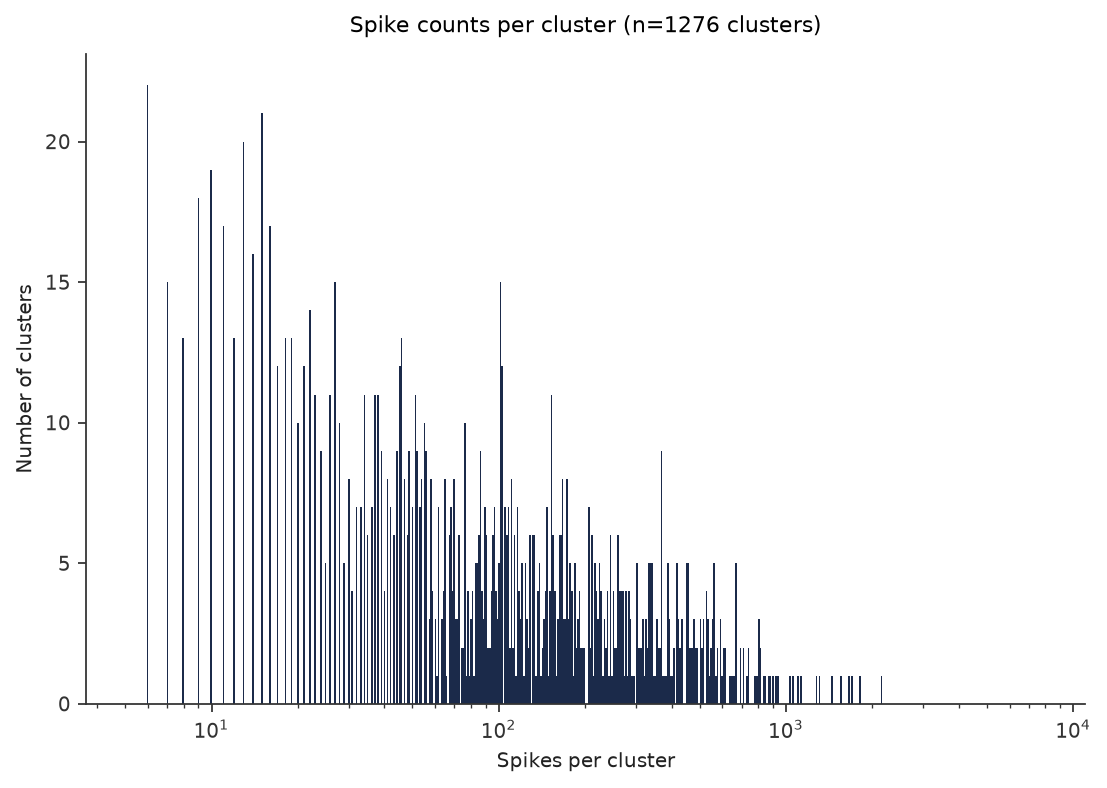

Saved: /gpfs/laur/personal/gongt/lab_meeting_plots/tomato_cluster_spike_count_histogram_before_merge.png


In [ ]:
"""
Cluster spike-count sanity check for an over-split sort (e.g. ToMATo output).

  1. Prints every cluster with more than PRINT_THRESHOLD spikes (the ones
     large enough to plausibly be real units, worth inspecting first).
  2. Histograms spike-count-per-cluster, dropping tiny clusters below
     MIN_SPIKES (mostly noise/leftover density peaks in an over-split sort)
     and, optionally, huge clusters above MAX_SPIKES (e.g. noise/hash blobs
     that would otherwise blow out the x-axis).
  3. Prints how many clusters clear MIN_SPIKES.

Just reads spike_clusters.npy -- no recording or raw data needed.
"""

from __future__ import annotations

import logging
from dataclasses import dataclass
from pathlib import Path
from typing import Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

logging.basicConfig(level=logging.INFO, format="%(message)s")
log = logging.getLogger("cluster_spike_counts")

# --------------------------------------------------------------------------- #
# Config -- edit these
# --------------------------------------------------------------------------- #

SORTER_OUTPUT = r"/gpfs/laur/data/0_collaboration/ceph_phys/GLC7189/GLC7189_c_g0/tomato_sorting/export_to_phy"

SAVE_DIR = Path("/gpfs/laur/personal/gongt/lab_meeting_plots")
OUT_NAME = "tomato_cluster_spike_count_histogram_before_merge.png"

PRINT_THRESHOLD = 300         # print every cluster with more spikes than this
MIN_SPIKES = 5                # clusters with fewer spikes than this are dropped entirely
                               # (from both the histogram and the ">=MIN_SPIKES" count)
MAX_SPIKES: Optional[int] = None  # clusters with MORE spikes than this are dropped from the
                                    # histogram (e.g. noise/hash blobs). None = no upper limit.

# If True, restrict everything below (the >PRINT_THRESHOLD list, the histogram,
# and the >=MIN_SPIKES count) to clusters manually curated as "good" in
# cluster_group.tsv. If that file doesn't exist yet (e.g. nothing's been
# curated in phy yet), this is reported and treated as "no good clusters".
ONLY_GOOD = True

LOG_SCALE_X = True           # spike counts are usually heavy-tailed -> log-spaced bins read better
N_BINS = 500


@dataclass
class PlotStyle:
    figsize: tuple = (7.0, 5.0)
    dpi: int = 160
    color: str = "#1b2a4a"


STYLE = PlotStyle()

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#333333",
    "axes.labelcolor": "#222222",
    "xtick.color": "#333333",
    "ytick.color": "#333333",
    "font.size": 9,
})


# --------------------------------------------------------------------------- #
# Main
# --------------------------------------------------------------------------- #

def load_spike_clusters(sorter_dir: str) -> np.ndarray:
    d = Path(sorter_dir)
    return np.load(d / "spike_clusters.npy").astype(int).ravel()


def load_good_cluster_ids(sorter_dir: str) -> set:
    path = Path(sorter_dir) / "cluster_group.tsv"
    if not path.exists():
        log.warning(f"ONLY_GOOD=True but {path} doesn't exist -- nothing has been "
                     "curated yet, so there are no 'good' clusters to filter to.")
        return set()
    df = pd.read_csv(path, sep="\t")
    if "label" not in df.columns:
        print("label" not in df.columns)
        log.warning("cluster_group.tsv has no 'label' column -- treating as no good clusters.")
        return set()
    id_col = "cluster_id" if "cluster_id" in df.columns else df.columns[0]
    return {int(cid) for cid, g in zip(df[id_col], df["label"]) if str(g).lower() == "good"}


def main() -> None:
    spike_clusters = load_spike_clusters(SORTER_OUTPUT)
    cluster_ids, counts = np.unique(spike_clusters, return_counts=True)
    log.info("%d total clusters, %d total spikes", len(cluster_ids), len(spike_clusters))

    if ONLY_GOOD:
        good_ids = load_good_cluster_ids(SORTER_OUTPUT)
        log.info("Restricting to %d clusters curated as 'good'", len(good_ids))
        keep = np.isin(cluster_ids, list(good_ids))
        cluster_ids, counts = cluster_ids[keep], counts[keep]
        if cluster_ids.size == 0:
            log.warning("No 'good' clusters found -- nothing to print or plot. "
                        "Set ONLY_GOOD = False to see everything instead.")
            return

    # 1) clusters with > PRINT_THRESHOLD spikes
    big_mask = counts > PRINT_THRESHOLD
    order = np.argsort(counts[big_mask])[::-1]  # largest first
    big_ids = cluster_ids[big_mask][order]
    big_counts = counts[big_mask][order]

    log.info("")
    log.info("%d clusters with > %d spikes:", len(big_ids), PRINT_THRESHOLD)
    for cid, c in zip(big_ids, big_counts):
        log.info("  cluster %5d: %d spikes", cid, c)

    # 2) how many clusters clear MIN_SPIKES, and histogram of those
    #    (MIN_SPIKES/MAX_SPIKES only affect the histogram + this printed count,
    #    not the >PRINT_THRESHOLD list above)
    keep_mask = counts >= MIN_SPIKES
    if MAX_SPIKES is not None:
        keep_mask &= counts <= MAX_SPIKES
    kept_counts = counts[keep_mask]

    log.info("")
    range_desc = f">= {MIN_SPIKES}" + (f" and <= {MAX_SPIKES}" if MAX_SPIKES is not None else "")
    log.info("%d / %d clusters have %s spikes (the rest are dropped as noise/leftover peaks%s)",
              keep_mask.sum(), len(cluster_ids), range_desc,
              " or huge outlier blobs" if MAX_SPIKES is not None else "")
    if MAX_SPIKES is not None:
        n_dropped_huge = int(np.sum(counts > MAX_SPIKES))
        if n_dropped_huge:
            log.info("  (%d clusters excluded for having > %d spikes)", n_dropped_huge, MAX_SPIKES)

    if kept_counts.size == 0:
        log.warning("No clusters clear MIN_SPIKES=%d%s -- nothing to histogram.",
                    MIN_SPIKES, f"/MAX_SPIKES={MAX_SPIKES}" if MAX_SPIKES is not None else "")
        return

    fig, ax = plt.subplots(figsize=STYLE.figsize, dpi=STYLE.dpi)

    if LOG_SCALE_X and kept_counts.max() > kept_counts.min():
        bins = np.logspace(np.log10(kept_counts.min()), np.log10(kept_counts.max()), N_BINS)
        ax.set_xscale("log")
    else:
        bins = N_BINS

    ax.hist(kept_counts, bins=bins, color=STYLE.color, edgecolor="none")
    ax.set_xlim(left=0, right=11000)
    ax.set_xlabel("Spikes per cluster")
    ax.set_ylabel("Number of clusters")
    ax.set_title(f"Spike counts per cluster (n={keep_mask.sum()} clusters)", fontsize=10, pad=10)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    fig.tight_layout()
    SAVE_DIR.mkdir(parents=True, exist_ok=True)
    out_path = SAVE_DIR / OUT_NAME
    fig.savefig(out_path, dpi=STYLE.dpi, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    log.info("Saved: %s", out_path)


if __name__ == "__main__":
    main()